In [1]:
x=1

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from anndata import AnnData
from plottable import ColumnDefinition, Table
from plottable.cmap import normed_cmap
from plottable.plots import bar

/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx ins

In [3]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt

def cmap_map(function, cmap):
    """ Applies function (which should operate on vectors of shape 3: [r, g, b]), on colormap cmap.
    This routine will break any discontinuous points in a colormap.
    """
    cdict = cmap._segmentdata
    step_dict = {}
    # Firt get the list of points where the segments start or end
    for key in ('red', 'green', 'blue'):
        step_dict[key] = list(map(lambda x: x[0], cdict[key]))
    step_list = sum(step_dict.values(), [])
    step_list = np.array(list(set(step_list)))
    # Then compute the LUT, and apply the function to the LUT
    reduced_cmap = lambda step : np.array(cmap(step)[0:3])
    old_LUT = np.array(list(map(reduced_cmap, step_list)))
    new_LUT = np.array(list(map(function, old_LUT)))
    # Now try to make a minimal segment definition of the new LUT
    cdict = {}
    for i, key in enumerate(['red','green','blue']):
        this_cdict = {}
        for j, step in enumerate(step_list):
            if step in step_dict[key]:
                this_cdict[step] = new_LUT[j, i]
            elif new_LUT[j,i] != old_LUT[j, i]:
                this_cdict[step] = new_LUT[j, i]
        colorvector = list(map(lambda x: x + (x[1], ), this_cdict.items()))
        colorvector.sort()
        cdict[key] = colorvector

    return matplotlib.colors.LinearSegmentedColormap('colormap',cdict,1024)

In [4]:
light_cmap = cmap_map(lambda x: x/2 + 0.5, matplotlib.cm.YlGnBu)

In [5]:
df_type = {
    'ARI': 'Bio conservation',
    'NMI': 'Bio conservation',
    'Label ASW': 'Bio conservation',
    'Isolated label ASW': 'Bio conservation',
    'Batch ASW': 'Batch correction',
    'Graph Connectivity': 'Batch correction',
    'Bio conservation': 'Aggregate score',
    'Batch correction': 'Aggregate score',
    'Total': 'Aggregate score',
}
df_type = pd.DataFrame(df_type, index=['Metric Type'])
df_type

,ARI,NMI,Label ASW,Isolated label ASW,Batch ASW,Graph Connectivity,Bio conservation,Batch correction,Total
Metric Type,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Batch correction,Batch correction,Aggregate score,Aggregate score,Aggregate score


In [6]:
df_pca = pd.read_csv('/lustre/groups/ml01/workspace/anastasia.litinetskaya/code/multimil_reproducibility/pbmc/data/pca_3_cond_balanced.csv', index_col=0, header=0)
df_pca = df_pca.dropna()
df_pca = df_pca.T
df_pca = df_pca.rename(index={'0': 'PCA'})
df_pca

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,isolated_label_silhouette,graph_conn
PCA,0.59163,0.379326,0.499002,0.867534,0.564419,0.717197


In [7]:
df_scgpt = pd.read_csv('/lustre/groups/ml01/workspace/anastasia.litinetskaya/code/multimil_reproducibility/pbmc/data/scgpt_embeddings_3_cond_balanced.csv', index_col=0, header=0)
df_scgpt = df_scgpt.dropna()
df_scgpt = df_scgpt.T
df_scgpt = df_scgpt.rename(index={'0': 'scGPT'})
df_scgpt

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,isolated_label_silhouette,graph_conn
scGPT,0.673805,0.504387,0.510613,0.894101,0.535475,0.694545


In [8]:
df_gf = pd.read_csv('/lustre/groups/ml01/workspace/anastasia.litinetskaya/code/multimil_reproducibility/pbmc/data/geneformer_embeddings_3_cond_balanced.csv', index_col=0, header=0)
df_gf = df_gf.dropna()
df_gf = df_gf.T
df_gf = df_gf.rename(index={'0': 'GeneFormer'})
df_gf

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,isolated_label_silhouette,graph_conn
GeneFormer,0.535809,0.265462,0.475427,0.920687,0.510538,0.488288


In [9]:
df_scvi = pd.read_csv('/lustre/groups/ml01/workspace/anastasia.litinetskaya/code/multimil_reproducibility/pbmc/data/scvi_latent_3_cond_balanced.csv', index_col=0, header=0)
df_scvi = df_scvi.dropna()
df_scvi = df_scvi.T
df_scvi = df_scvi.rename(index={'0': 'scVI'})
df_scvi

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,isolated_label_silhouette,graph_conn
scVI,0.674298,0.54456,0.510872,0.929903,0.551194,0.701149


In [10]:
df = pd.concat([df_gf, df_scvi, df_pca, df_scgpt])
df

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,isolated_label_silhouette,graph_conn
GeneFormer,0.535809,0.265462,0.475427,0.920687,0.510538,0.488288
scVI,0.674298,0.544560,0.510872,0.929903,0.551194,0.701149
PCA,0.591630,0.379326,0.499002,0.867534,0.564419,0.717197
scGPT,0.673805,0.504387,0.510613,0.894101,0.535475,0.694545


In [11]:
df = df.rename(columns={
    'NMI_cluster/label': 'NMI', 
    'ARI_cluster/label': 'ARI',
    'ASW_label': 'Label ASW',
    'ASW_label/batch': 'Batch ASW',
    'isolated_label_silhouette': 'Isolated label ASW',
    'graph_conn': 'Graph Connectivity',
})

In [12]:
df.loc[:, 'Bio conservation'] = np.mean([df.loc[:, 'ARI'], df.loc[:, 'NMI'], df.loc[:, 'Isolated label ASW'], df.loc[:, 'Label ASW']], axis=0)
df

,NMI,ARI,Label ASW,Batch ASW,Isolated label ASW,Graph Connectivity,Bio conservation
GeneFormer,0.535809,0.265462,0.475427,0.920687,0.510538,0.488288,0.446809
scVI,0.674298,0.544560,0.510872,0.929903,0.551194,0.701149,0.570231
PCA,0.591630,0.379326,0.499002,0.867534,0.564419,0.717197,0.508594
scGPT,0.673805,0.504387,0.510613,0.894101,0.535475,0.694545,0.556070


In [13]:
df.loc[:, 'Batch correction'] = np.mean([df.loc[:, 'Batch ASW'], df.loc[:, 'Graph Connectivity']], axis=0)
df

,NMI,ARI,Label ASW,Batch ASW,Isolated label ASW,Graph Connectivity,Bio conservation,Batch correction
GeneFormer,0.535809,0.265462,0.475427,0.920687,0.510538,0.488288,0.446809,0.704487
scVI,0.674298,0.544560,0.510872,0.929903,0.551194,0.701149,0.570231,0.815526
PCA,0.591630,0.379326,0.499002,0.867534,0.564419,0.717197,0.508594,0.792366
scGPT,0.673805,0.504387,0.510613,0.894101,0.535475,0.694545,0.556070,0.794323


In [14]:
df.loc[:, 'Total'] = 0.6 * df.loc[:, 'Bio conservation'] + 0.4 * df.loc[:, 'Batch correction']

In [15]:
df = pd.concat([df, df_type])

In [16]:
score_cols = df.columns[df.loc['Metric Type'] == 'Aggregate score']
other_cols = df.columns[df.loc['Metric Type'] != 'Aggregate score']

In [17]:
plot_df = df.drop('Metric Type', axis=0)

In [18]:
plot_df = plot_df.sort_values(by="Total", ascending=False).astype(np.float64)

In [19]:
plot_df["Method"] = plot_df.index

In [20]:
column_definitions = [
    ColumnDefinition("Method", width=1.5, textprops={"ha": "left", "weight": "bold"}),
]

In [21]:
df = df.loc[:, ['NMI', 'ARI', 'Label ASW', 'Isolated label ASW', 'Batch ASW', 'Graph Connectivity', 'Bio conservation', 'Batch correction', 'Total']]
df

,NMI,ARI,Label ASW,Isolated label ASW,Batch ASW,Graph Connectivity,Bio conservation,Batch correction,Total
GeneFormer,0.535809,0.265462,0.475427,0.510538,0.920687,0.488288,0.446809,0.704487,0.54988
scVI,0.674298,0.54456,0.510872,0.551194,0.929903,0.701149,0.570231,0.815526,0.668349
PCA,0.59163,0.379326,0.499002,0.564419,0.867534,0.717197,0.508594,0.792366,0.622103
scGPT,0.673805,0.504387,0.510613,0.535475,0.894101,0.694545,0.55607,0.794323,0.651371
Metric Type,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Batch correction,Batch correction,Aggregate score,Aggregate score,Aggregate score


In [22]:
plot_df = plot_df.loc[:, ['NMI', 'ARI', 'Label ASW', 'Isolated label ASW', 'Batch ASW', 'Graph Connectivity', 'Bio conservation', 'Batch correction', 'Total', 'Method']]
plot_df

,NMI,ARI,Label ASW,Isolated label ASW,Batch ASW,Graph Connectivity,Bio conservation,Batch correction,Total,Method
scVI,0.674298,0.544560,0.510872,0.551194,0.929903,0.701149,0.570231,0.815526,0.668349,scVI
scGPT,0.673805,0.504387,0.510613,0.535475,0.894101,0.694545,0.556070,0.794323,0.651371,scGPT
PCA,0.591630,0.379326,0.499002,0.564419,0.867534,0.717197,0.508594,0.792366,0.622103,PCA
GeneFormer,0.535809,0.265462,0.475427,0.510538,0.920687,0.488288,0.446809,0.704487,0.549880,GeneFormer


In [23]:
cmap_fn = lambda col_data: normed_cmap(col_data, cmap=matplotlib.cm.PRGn, num_stds=2.5)

# Circles for the metric values
column_definitions += [
    ColumnDefinition(
        col,
        title=col.replace(" ", "\n", 1),
        width=1,
        textprops={
            "ha": "center",
            "bbox": {"boxstyle": "circle", "pad": 0.25},
        },
        cmap=cmap_fn(plot_df[col]),
        group=df.loc['Metric Type', col],
        formatter="{:.2f}",
    )
    for i, col in enumerate(other_cols)
]

In [24]:
cmap_fn = lambda col_data: normed_cmap(col_data, cmap=light_cmap, num_stds=2.5)

# Bars for the aggregate scores
column_definitions += [
    ColumnDefinition(
        col,
        width=1,
        title=col.replace(" ", "\n", 1),
        plot_fn=bar,
        plot_kw={
            "cmap": cmap_fn(plot_df[col]),
            "plot_bg_bar": False,
            "annotate": True,
            "height": 0.9,
            "formatter": "{:.2f}",
        },
        group=df.loc['Metric Type', col],
        border="left" if i == 0 else None,
    )
    for i, col in enumerate(score_cols)
]

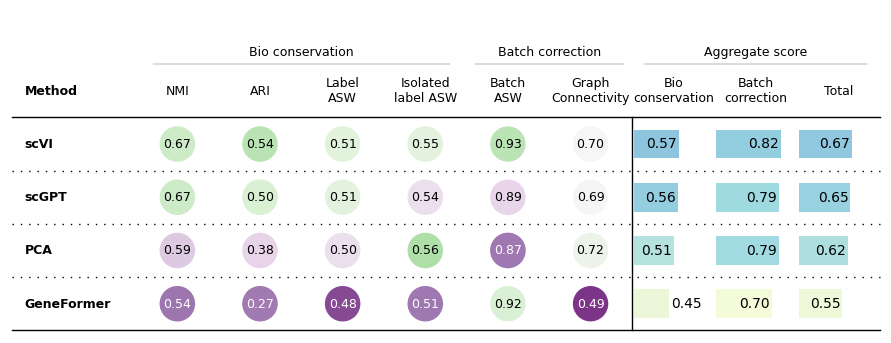

In [25]:
num_embeds = len(plot_df)

# Allow to manipulate text post-hoc (in illustrator)
with matplotlib.rc_context({"svg.fonttype": "none"}):
    fig, ax = plt.subplots(figsize=(len(df.columns) * 1.25, 3 + 0.3 * num_embeds))
    tab = Table(
        plot_df,
        cell_kw={
            "linewidth": 0,
            "edgecolor": "k",
        },
        column_definitions=column_definitions,
        ax=ax,
        row_dividers=True,
        footer_divider=True,
        textprops={"fontsize": 9, "ha": "center"},
        row_divider_kw={"linewidth": 1, "linestyle": (0, (1, 5))},
        col_label_divider_kw={"linewidth": 1, "linestyle": "-"},
        column_border_kw={"linewidth": 1, "linestyle": "-"},
        index_col="Method",
    ).autoset_fontcolors(colnames=plot_df.columns)

plt.savefig('figures/scib_table_embeds_all.svg', bbox_inches='tight')

plt.show()